<div dir="rtl" align="right">

# סעיף 1: טעינת הנתונים והמרת סוגי משתנים

</div>

In [ ]:
# Load the dataset (before any cleaning)
import pandas as pd

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')  # show full numbers, not scientific notation

df = pd.read_csv('ks-projects-201801.csv')
df['deadline'] = pd.to_datetime(df['deadline'])   # convert text to real datetime
df['launched'] = pd.to_datetime(df['launched'])   # convert text to real datetime

<div dir="rtl" align="right">

טענו את קובץ הנתונים `ks-projects-201801.csv` והמרנו את עמודות `deadline` ו-`launched`
לפורמט `datetime` אמיתי. ההמרה הזו היא תנאי לחישובי הזמן שנעשה בהמשך — בלעדיה לא נוכל
לחשב את משך הקמפיין או לחלץ את חודש ההשקה.

</div>

<div dir="rtl" align="right">

# סעיף 2: היכרות עם העמודות וסוגי הנתונים

</div>

In [ ]:
display(df.head())
print(df.shape)

# Column names, data types and non-null counts
df.info()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,"1,000.00",2015-08-11 12:12:28,0.00,failed,0,GB,0.00,0.00,"1,533.95"
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,"30,000.00",2017-09-02 04:43:57,"2,421.00",failed,15,US,100.00,"2,421.00","30,000.00"
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,"45,000.00",2013-01-12 00:20:50,220.00,failed,3,US,220.00,220.00,"45,000.00"
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,"5,000.00",2012-03-17 03:24:11,1.00,failed,1,US,1.00,1.00,"5,000.00"
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,"19,500.00",2015-07-04 08:35:03,"1,283.00",canceled,14,US,"1,283.00","1,283.00","19,500.00"


(378661, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   ID                378661 non-null  int64         
 1   name              378657 non-null  object        
 2   category          378661 non-null  object        
 3   main_category     378661 non-null  object        
 4   currency          378661 non-null  object        
 5   deadline          378661 non-null  datetime64[ns]
 6   goal              378661 non-null  float64       
 7   launched          378661 non-null  datetime64[ns]
 8   pledged           378661 non-null  float64       
 9   state             378661 non-null  object        
 10  backers           378661 non-null  int64         
 11  country           378661 non-null  object        
 12  usd pledged       374864 non-null  float64       
 13  usd_pledged_real  378661 non-null  float64    

<div dir="rtl" align="right">

סקרנו את שמות העמודות ואת סוגי המשתנים (מספריים מול קטגוריאליים). הקובץ מכיל 378,661 שורות
ו-15 עמודות.

שמנו לב שהמשתנים הכספיים מופיעים במטבעות שונים (`goal`, `pledged`), ולכן נשתמש לאורך כל
העבודה בעמודות `usd_goal_real` ו-`usd_pledged_real` שכבר מנורמלות לדולר.

</div>

<div dir="rtl" align="right">

# סעיף 3: סטטיסטיקה תיאורית ראשונית

</div>

In [ ]:
df.describe()

,ID,deadline,goal,launched,pledged,backers,usd pledged,usd_pledged_real,usd_goal_real
count,"378,661.00",378661,"378,661.00",378661,"378,661.00","378,661.00","374,864.00","378,661.00","378,661.00"
mean,"1,074,731,191.99",2014-11-01 16:04:27.950488832,"49,080.79",2014-09-28 18:06:17.416520448,"9,682.98",105.62,"7,036.73","9,058.92","45,454.40"
min,"5,971.00",2009-05-03 00:00:00,0.01,1970-01-01 01:00:00,0.00,0.00,0.00,0.00,0.01
25%,"538,263,516.00",2013-06-08 00:00:00,"2,000.00",2013-05-07 22:14:27,30.00,2.00,16.98,31.00,"2,000.00"
50%,"1,075,275,634.00",2015-01-14 00:00:00,"5,200.00",2014-12-10 03:23:41,620.00,12.00,394.72,624.33,"5,500.00"
75%,"1,610,148,624.00",2016-04-28 00:00:00,"16,000.00",2016-03-24 10:21:09,"4,076.00",56.00,"3,034.09","4,050.00","15,500.00"
max,"2,147,476,221.00",2018-03-03 00:00:00,"100,000,000.00",2018-01-02 15:02:31,"20,338,986.27","219,382.00","20,338,986.27","20,338,986.27","166,361,390.71"
std,"619,086,204.32",NaN,"1,183,391.26",NaN,"95,636.01",907.19,"78,639.75","90,973.34","1,152,950.06"


<div dir="rtl" align="right">

הפקנו מדדי מרכז ופיזור (ממוצע, חציון, סטיית תקן) כדי להבין את טווחי הערכים.

הממצא הבולט הוא הפער העצום בין הממוצע לחציון ביעד הגיוס: ממוצע של כ-45,000 דולר מול חציון
של 5,500 דולר. פער כזה מעיד על התפלגות א-סימטרית עם זנב ימני כבד, וזו הסיבה שבהמשך נחיל
טרנספורמציית לוג על המשתנה הזה.

</div>

<div dir="rtl" align="right">

# סעיף 4: בדיקת ערכים חסרים

</div>

In [ ]:
# Missing values per column
print(df.isnull().sum())

ID                     0
name                   4
category               0
main_category          0
currency               0
deadline               0
goal                   0
launched               0
pledged                0
state                  0
backers                0
country                0
usd pledged         3797
usd_pledged_real       0
usd_goal_real          0
dtype: int64


<div dir="rtl" align="right">

בדקנו את כמות הערכים החסרים בכל עמודה. רוב הנתונים מלאים לחלוטין: 3,797 ערכים חסרים
בעמודת `usd pledged` וארבע שורות ללא שם פרויקט.

שתי העמודות האלה אינן נכנסות למודל — `usd pledged` היא משתנה דליפה (מידע שנוצר במהלך
הקמפיין), ו-`name` הוא טקסט חופשי שאיננו מנתחים. לכן החוסרים אינם משפיעים על המשתנים
המסבירים שבחרנו.

</div>

<div dir="rtl" align="right">

# סעיף 5 א': ויזואליזציה של קשרים (Scatter Matrix)

</div>

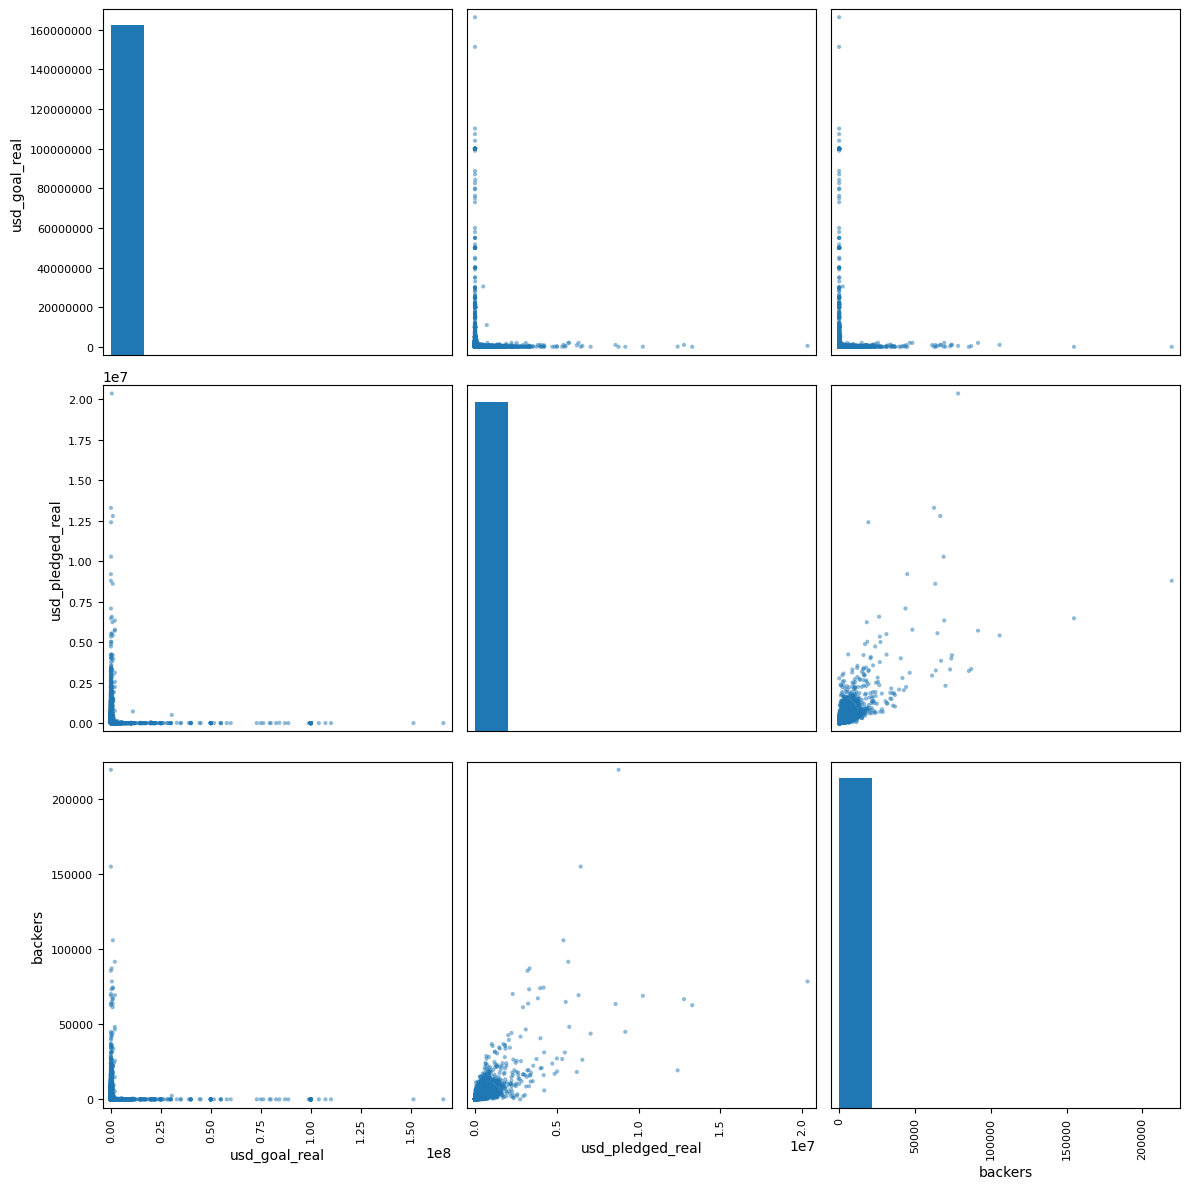

In [ ]:
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt

# Standardizing variables to USD real values for consistent scale
vars_to_plot = ['usd_goal_real', 'usd_pledged_real', 'backers']

# Create the scatter matrix plot
scatter_matrix(df[vars_to_plot], figsize=(12, 12), alpha=0.5)

# Finalize layout for display
plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

יצרנו מטריצת פיזור כדי לבחון את הקשרים בין המשתנים הכספיים למספר התומכים. זיהינו מתאם
חיובי חזק בין מספר התומכים לסכום שגויס בפועל.

חשוב להדגיש: דווקא בגלל שהקשר הזה כל כך חזק, `backers` ו-`pledged` **לא** ייכנסו למודל.
אלה משתנים שנוצרים במהלך הקמפיין ולא זמינים ליזם בזמן קבלת ההחלטה, ולכן שימוש בהם היה
יוצר דליפת מידע (Data Leakage) ומודל חסר ערך מעשי.

</div>

<div dir="rtl" align="right">

# סעיף 5 ב': ניתוח התפלגויות

</div>

<div dir="rtl" align="right">

### ההתפלגות המקורית של יעד הגיוס — לפני טרנספורמציית הלוג

לפני שאנחנו מחילים לוג, כדאי לראות למה בכלל צריך אותו. הגרף הבא מציג את `usd_goal_real`
בסקאלה המקורית בדולרים.

</div>

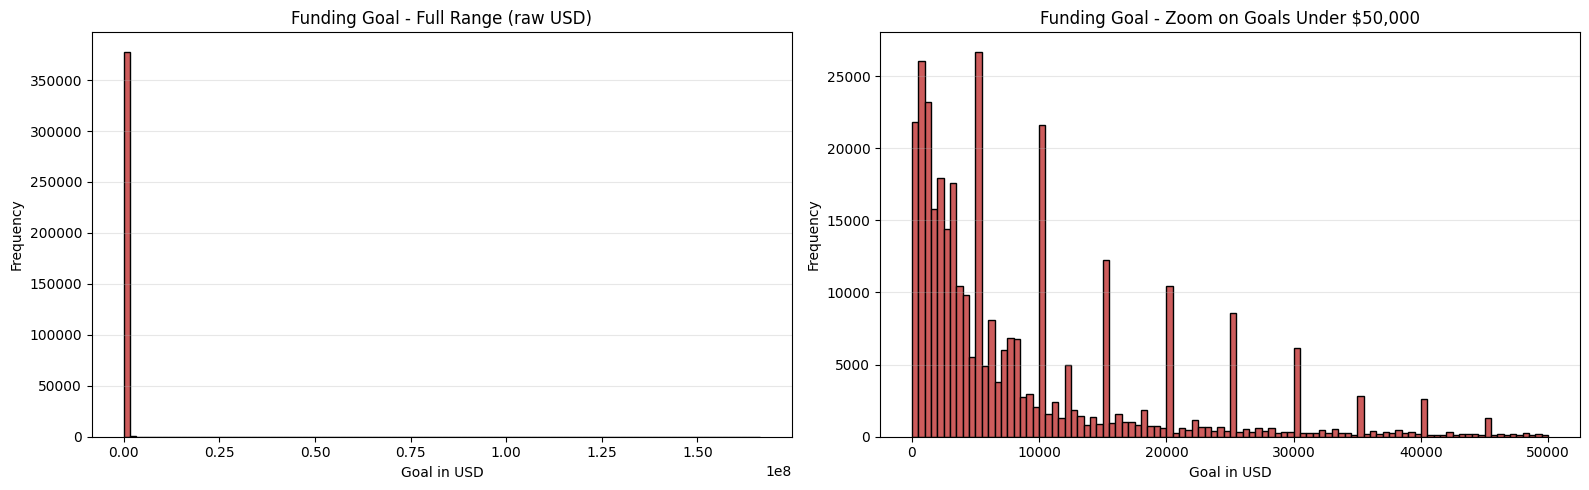

Mean:                     45,454 USD
Median:                    5,500 USD
Max:                 166,361,391 USD
Mean / Median:               8.3x
Share of campaigns under $50,000: 90.4%


In [ ]:
# Distribution of the funding goal BEFORE the log transform - showing the long tail
import numpy as np
import matplotlib.pyplot as plt

goal = df['usd_goal_real']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: the full range. The tail stretches to 166M, so everything collapses into one bar
axes[0].hist(goal, bins=100, color='indianred', edgecolor='black')
axes[0].set_title('Funding Goal - Full Range (raw USD)')
axes[0].set_xlabel('Goal in USD')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', alpha=0.3)

# Right: zoom in on goals under 50,000 USD, where almost all campaigns actually sit
axes[1].hist(goal[goal < 50_000], bins=100, color='indianred', edgecolor='black')
axes[1].set_title('Funding Goal - Zoom on Goals Under $50,000')
axes[1].set_xlabel('Goal in USD')
axes[1].set_ylabel('Frequency')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean:            {goal.mean():>15,.0f} USD")
print(f"Median:          {goal.median():>15,.0f} USD")
print(f"Max:             {goal.max():>15,.0f} USD")
print(f"Mean / Median:   {goal.mean() / goal.median():>15,.1f}x")
print(f"Share of campaigns under $50,000: {(goal < 50_000).mean() * 100:.1f}%")


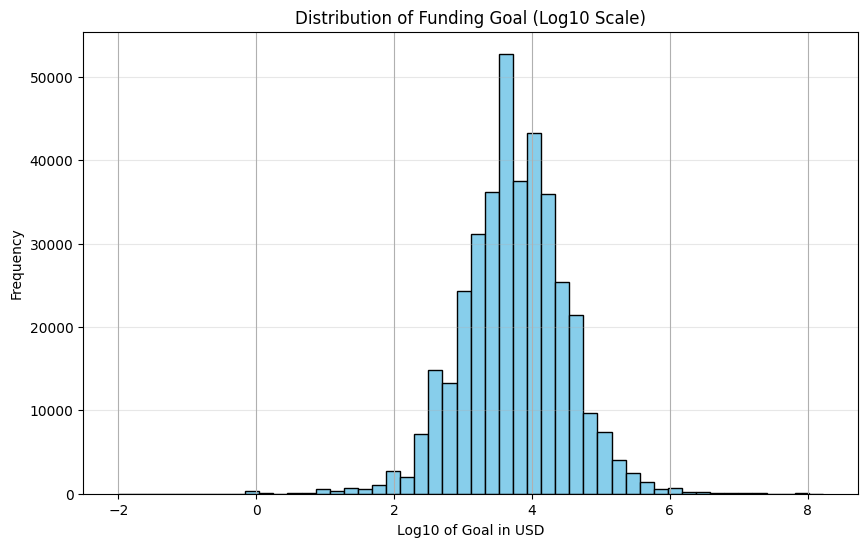

In [ ]:
# 1. Distribution of Funding Goal (usd_goal_real)
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
# Using log10 to handle extreme ranges in goals
df['usd_goal_real'].apply(lambda x: np.log10(x) if x > 0 else 0).hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Funding Goal (Log10 Scale)')
plt.xlabel('Log10 of Goal in USD')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.show()

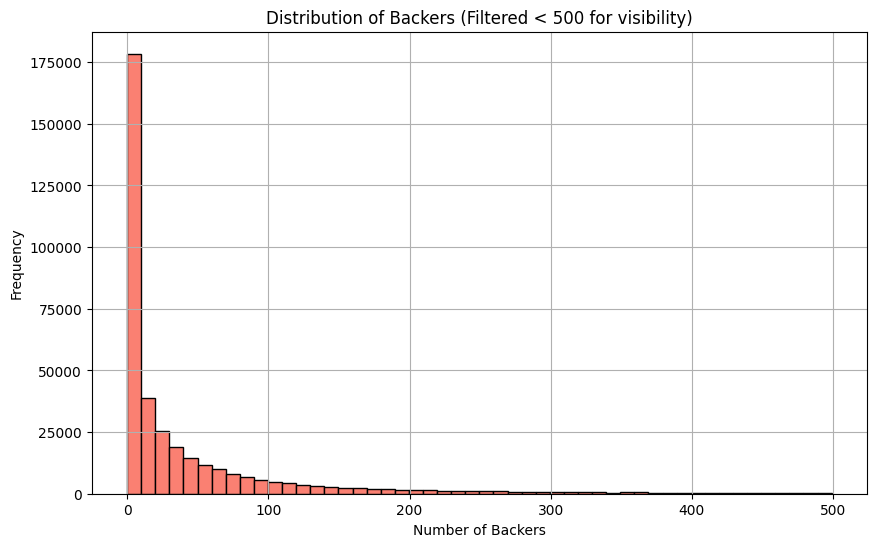

In [ ]:
# 2. Distribution of Backers
plt.figure(figsize=(10, 6))
# Filtering for backers < 500 to see the main distribution clearly
df[df['backers'] < 500]['backers'].hist(bins=50, color='salmon', edgecolor='black')
plt.title('Distribution of Backers (Filtered < 500 for visibility)')
plt.xlabel('Number of Backers')
plt.ylabel('Frequency')
plt.show()

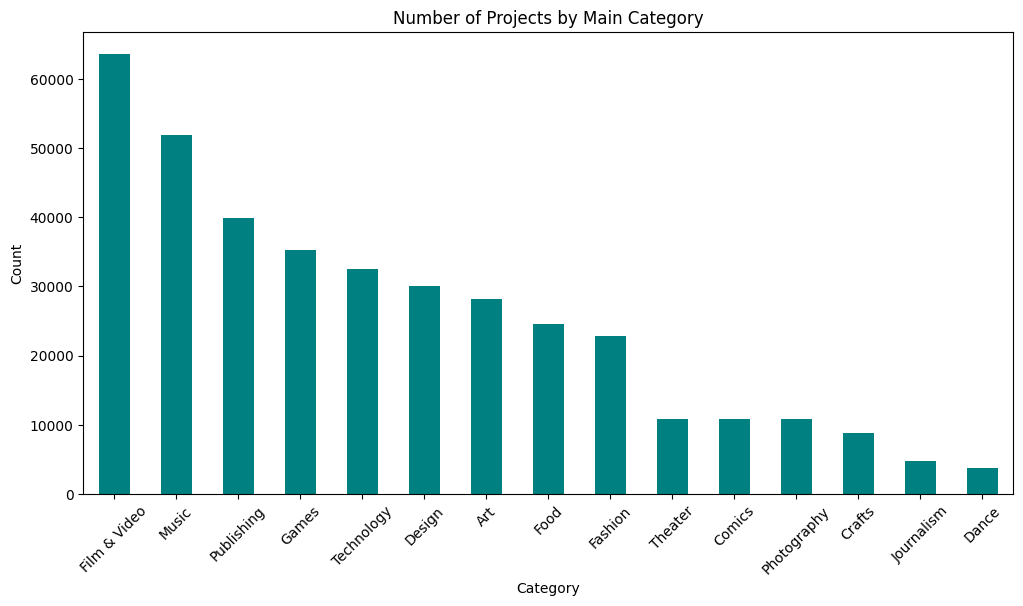

In [ ]:
# 3. Main Categories Frequency
plt.figure(figsize=(12, 6))
df['main_category'].value_counts().plot(kind='bar', color='teal')
plt.title('Number of Projects by Main Category')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

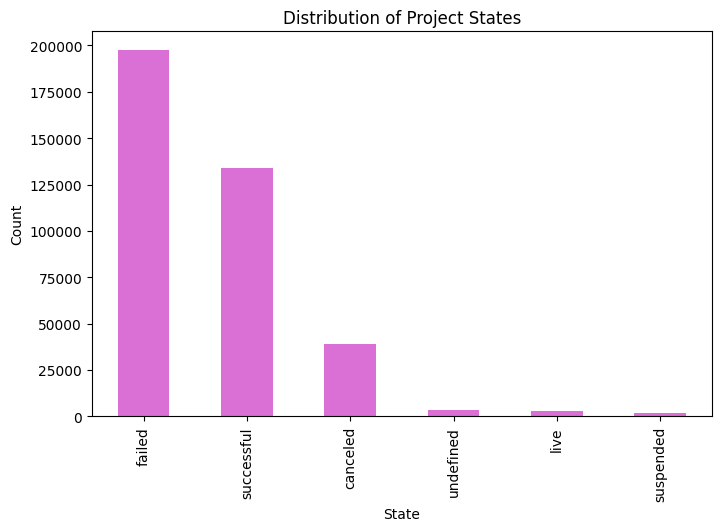

In [ ]:
# 4. Target Variable Distribution (State)
plt.figure(figsize=(8, 5))
df['state'].value_counts().plot(kind='bar', color='orchid')
plt.title('Distribution of Project States')
plt.xlabel('State')
plt.ylabel('Count')
plt.show()

<div dir="rtl" align="right">

ניתחנו את ההתפלגויות של יעד הגיוס, מספר התומכים, הקטגוריות ומשתנה המטרה.

עלו שני ממצאים מרכזיים: ראשית, יעד הגיוס מתפלג בזנב ארוך מאוד — רוב הפרויקטים מבקשים
סכומים צנועים ומיעוט קטן מבקש מיליונים, ולכן הגרף בסקאלה רגילה אינו קריא והלוג הכרחי.
שנית, רוב הפרויקטים נכשלים, כלומר משתנה המטרה אינו מאוזן.

</div>

<div dir="rtl" align="right">

## סעיף 6 א': בחירת המשתנים לפרויקט

#### הגדרת המשתנים

*   **Y (המשתנה הנחזה):** סטטוס הפרויקט (`state`) — האם הצליח (`successful`) או נכשל (`failed`).
*   **X (המשתנים המסבירים):**
    1. **יעד גיוס ריאלי (`usd_goal_real`):** משתנה מספרי, יעבור טרנספורמציית לוג.
    2. **קטגוריה ראשית (`main_category`):** דורש המרה למספרי באמצעות One-Hot Encoding.
    3. **משך הקמפיין:** ההפרש בין `deadline` ל-`launched`, בימים.
    4. **חודש ההשקה:** מחולץ מתוך `launched`, ומקודד כמשתנה קטגוריאלי ולא רציף.

#### הסבר

בחרנו במשתנים האלה מסיבה אחת מרכזית: כולם זמינים ליזם **לפני** תחילת הקמפיין. זו ההחלטה
המתודולוגית החשובה ביותר בפרויקט. מודל שמשתמש ב-`backers` או ב-`pledged` יגיע לדיוק גבוה
בהרבה, אבל יהיה חסר ערך מסחרי — היזם לא מחזיק במספרים האלה ברגע שבו הוא צריך להחליט.

יעד גיוס ריאלי וקטגוריה מתאימה הם גורמים שהיזם שולט בהם, ומשך הקמפיין מאפשר לבדוק אם
קמפיינים ארוכים או קצרים נוטים להצליח יותר.

</div>

<div dir="rtl" align="right">

# סעיף 6 ב': המרת משתנים קטגוריאליים למספריים

</div>

In [ ]:
import numpy as np

# 1. Filtering for binary classification
df = df[df['state'].isin(['successful', 'failed'])].copy()

# 2. Feature Engineering: Duration and Month
df['duration_days'] = (df['deadline'] - df['launched']).dt.days
df['launch_month'] = df['launched'].dt.month

# 3. One-Hot Encoding for main_category
category_dummies = pd.get_dummies(df['main_category'], prefix='cat')
df[category_dummies.columns] = category_dummies  # assignment instead of concat, so re-running does not duplicate columns

# 4. Convert target variable to binary (0 and 1)
df['target'] = df['state'].map({'successful': 1, 'failed': 0})

# 5. Remove non-predictive column (using errors='ignore' to prevent KeyError if already dropped)
df = df.drop(columns=['name'], errors='ignore')

# Applying logarithmic transformation to funding goal (to handle identified outliers)
df['log_usd_goal'] = np.log1p(df['usd_goal_real'])

# Encoding launch month into Dummy variables (as month is a categorical, not continuous, variable)
month_dummies = pd.get_dummies(df['launch_month'], prefix='month')
df[month_dummies.columns] = month_dummies  # assignment instead of concat, so re-running does not duplicate columns

# Selecting final variables for the model (strict filtering of information-leaking variables like pledged and backers)
dummy_cols = [col for col in df.columns if col.startswith('cat_') or col.startswith('month_')]
features = ['log_usd_goal', 'duration_days'] + dummy_cols

X = df[features].copy()
y = df['target'].copy()

# Handle NaN values in features before splitting and scaling
X.dropna(inplace=True)
y = y.loc[X.index] # Ensure y matches the rows remaining in X

print("Final features shape:", X.shape)

Final features shape: (331675, 29)


<div dir="rtl" align="right">

# סעיף 7: ניתוח המשתנים שנבחרו

</div>

In [ ]:
# Selected variables for analysis
selected_features = ['usd_goal_real', 'duration_days', 'launch_month', 'target']

# Descriptive statistics
print("Descriptive Statistics for Selected Features:")
display(df[selected_features].describe())

# Target variable distribution
print("\nTarget Distribution (1 = Successful, 0 = Failed):")
display(df['target'].value_counts())

print("\nTarget Percentages:")
print(df['target'].value_counts(normalize=True) * 100)

Descriptive Statistics for Selected Features:


,usd_goal_real,duration_days,launch_month,target
count,"331,675.00","331,675.00","331,675.00","331,675.00"
mean,"41,510.00",32.95,6.42,0.40
std,"1,108,929.66",12.71,3.31,0.49
min,0.01,0.00,1.00,0.00
25%,"2,000.00",29.00,4.00,0.00
50%,"5,000.00",29.00,6.00,0.00
75%,"15,000.00",35.00,9.00,1.00
max,"166,361,390.71",91.00,12.00,1.00



Target Distribution (1 = Successful, 0 = Failed):


,count
target,
0,197719
1,133956



Target Percentages:
target
0   59.61
1   40.39
Name: proportion, dtype: float64


<div dir="rtl" align="right">

# סעיף 8: בדיקת קורלציות

</div>

Correlations with Project Success (Target):
target              1.00
backers             0.13
pledged             0.11
usd_pledged_real    0.11
usd pledged         0.10
ID                 -0.00
launch_month       -0.01
usd_goal_real      -0.02
goal               -0.03
duration_days      -0.12
log_usd_goal       -0.22
Name: target, dtype: float64


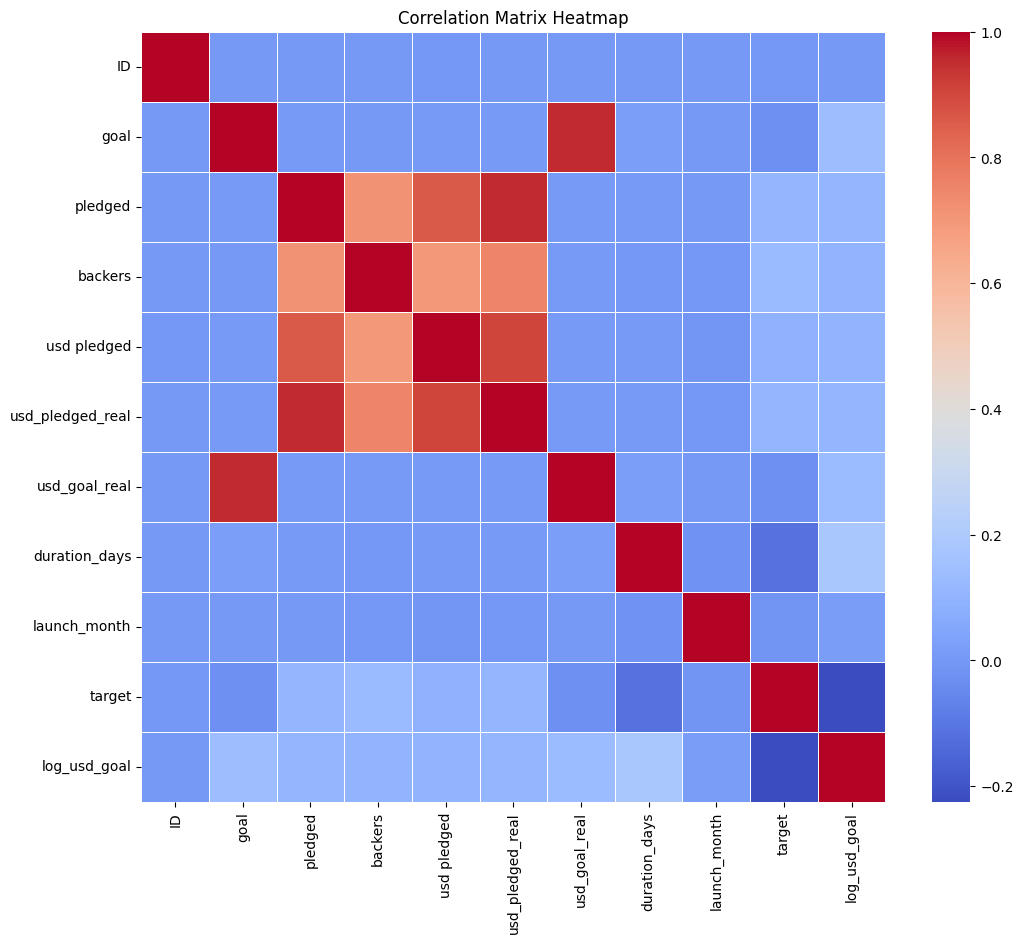

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select numeric columns (including target and engineered features)
numeric_df = df.select_dtypes(include=['number'])

# 2. Calculate correlations
corr_matrix = numeric_df.corr()

# 3. Focus on correlations with the target variable
print("Correlations with Project Success (Target):")
print(corr_matrix['target'].sort_values(ascending=False))

# 4. Visualize with a Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

<div dir="rtl" align="right">

## סעיף 9: פיצול וסקאלינג של הנתונים

נחלק את הנתונים לסט אימון (Training Set) וסט בדיקה (Test Set) ביחס 80/20, עם `stratify`
כדי לשמר את יחס ההצלחה/כישלון בשתי הקבוצות.

בנוסף נבצע סקאלינג (Standardization) באמצעות `StandardScaler`. חשוב: ה-scaler מאומן על סט
האימון בלבד ומוחל על סט המבחן, כדי שלא ידלוף מידע מסט המבחן אל תהליך האימון.

</div>

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Split data (80% training, 20% testing). Using stratify preserves the original success/failure ratio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Scale the data (Standardization)
scaler = StandardScaler()

# Important: Fit the scaler only on training data to avoid data leakage from test data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Prepare dictionaries to store results for all models to be run later
results = {}
roc_data = {}

print("Data is split and scaled! Ready for modeling.")
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

Data is split and scaled! Ready for modeling.
X_train shape: (265340, 29)
X_test shape: (66335, 29)


<div dir="rtl" align="right">

# **הכנת המודלים**

</div>

<div dir="rtl" align="right">

# הכנת מודל רגרסיה לוגיסטית (Logistic Regression)

</div>

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

# Define and train the model
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# Make predictions
y_pred_log = log_reg.predict(X_test_scaled)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

# Store metrics
results["Logistic Regression"] = {
    'Accuracy': accuracy_score(y_test, y_pred_log),
    'Precision': precision_score(y_test, y_pred_log),
    'Recall': recall_score(y_test, y_pred_log),
    'F1-Score': f1_score(y_test, y_pred_log),
    'ROC-AUC': roc_auc_score(y_test, y_prob_log)
}
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
roc_data["Logistic Regression"] = (fpr_log, tpr_log, results["Logistic Regression"]['ROC-AUC'])

print("1. Logistic Regression completed successfully!")

1. Logistic Regression completed successfully!


<div dir="rtl" align="right">

# הכנת מודל KNN (K-Nearest Neighbors)

</div>

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Define and train the model (using 5 neighbors as default)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]

# Store metrics
results["KNN"] = {
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn),
    'Recall': recall_score(y_test, y_pred_knn),
    'F1-Score': f1_score(y_test, y_pred_knn),
    'ROC-AUC': roc_auc_score(y_test, y_prob_knn)
}
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
roc_data["KNN"] = (fpr_knn, tpr_knn, results["KNN"]['ROC-AUC'])

print("2. KNN completed successfully!")

2. KNN completed successfully!


<div dir="rtl" align="right">

# הכנת מודל Naive Bayes

</div>

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Define and train the model
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

# Make predictions
y_pred_nb = nb.predict(X_test_scaled)
y_prob_nb = nb.predict_proba(X_test_scaled)[:, 1]

# Store metrics
results["Naive Bayes"] = {
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'Precision': precision_score(y_test, y_pred_nb),
    'Recall': recall_score(y_test, y_pred_nb),
    'F1-Score': f1_score(y_test, y_pred_nb),
    'ROC-AUC': roc_auc_score(y_test, y_prob_nb)
}
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
roc_data["Naive Bayes"] = (fpr_nb, tpr_nb, results["Naive Bayes"]['ROC-AUC'])

print("3. Naive Bayes completed successfully!")

3. Naive Bayes completed successfully!


<div dir="rtl" align="right">

# הכנת מודל עץ החלטה (Decision Tree)

</div>

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Define and train the model
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_scaled, y_train)

# Make predictions
y_pred_dt = dt.predict(X_test_scaled)
y_prob_dt = dt.predict_proba(X_test_scaled)[:, 1]

# Store metrics
results["Decision Tree"] = {
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall': recall_score(y_test, y_pred_dt),
    'F1-Score': f1_score(y_test, y_pred_dt),
    'ROC-AUC': roc_auc_score(y_test, y_prob_dt)
}
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
roc_data["Decision Tree"] = (fpr_dt, tpr_dt, results["Decision Tree"]['ROC-AUC'])

print("4. Decision Tree completed successfully!")

4. Decision Tree completed successfully!


<div dir="rtl" align="right">

# הכנת מודל Random Forest

</div>

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Define and train the model
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train_scaled, y_train)

# Make predictions
y_pred_rf = rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

# Store metrics
results["Random Forest"] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
}
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_data["Random Forest"] = (fpr_rf, tpr_rf, results["Random Forest"]['ROC-AUC'])

print("5. Random Forest completed successfully!")

5. Random Forest completed successfully!


<div dir="rtl" align="right">

# הכנת מודל Linear SVM (על תת-מדגם)

</div>

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

# Take a subsample of 5000 rows from the training data
# Using stratify ensures that the ratio of successful to failed campaigns remains the same in the subsample
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train_scaled, y_train, train_size=5000, random_state=42, stratify=y_train
)

# Train the model on the reduced sample
svm_model = SVC(kernel='linear', probability=True, random_state=42)
svm_model.fit(X_train_sub, y_train_sub)

# Make predictions on the entire test data as usual
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

# Store metrics
results["Linear SVM"] = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'Precision': precision_score(y_test, y_pred_svm),
    'Recall': recall_score(y_test, y_pred_svm),
    'F1-Score': f1_score(y_test, y_pred_svm),
    'ROC-AUC': roc_auc_score(y_test, y_prob_svm)
}

# Store data for the ROC plot
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
roc_data["Linear SVM"] = (fpr_svm, tpr_svm, results["Linear SVM"]['ROC-AUC'])

print("6. Linear SVM completed successfully on the subsample!")

6. Linear SVM completed successfully on the subsample!


<div dir="rtl" align="right">

# הכנת מודל XGBoost

</div>

In [ ]:
# Install the library in case it is not available in Colab
!pip install xgboost -q

from xgboost import XGBClassifier

# Define and train the model (a third tree-based model, based on Gradient Boosting)
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)
xgb_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test_scaled)
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

# Store metrics in the same dictionaries used by the previous models
results["XGBoost"] = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb),
    'Recall': recall_score(y_test, y_pred_xgb),
    'F1-Score': f1_score(y_test, y_pred_xgb),
    'ROC-AUC': roc_auc_score(y_test, y_prob_xgb)
}
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
roc_data["XGBoost"] = (fpr_xgb, tpr_xgb, results["XGBoost"]['ROC-AUC'])

print("7. XGBoost completed successfully!")

7. XGBoost completed successfully!


<div dir="rtl" align="right">

# השוואת ביצועי המודלים והצגת גרף ROC

</div>

Models Evaluation Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
XGBoost,0.665,0.609,0.473,0.533,0.710
Random Forest,0.650,0.619,0.350,0.447,0.695
Logistic Regression,0.646,0.590,0.402,0.478,0.680
Linear SVM,0.638,0.589,0.340,0.431,0.671
Decision Tree,0.636,0.590,0.323,0.418,0.657
Naive Bayes,0.621,0.528,0.581,0.553,0.651
KNN,0.620,0.534,0.466,0.498,0.636


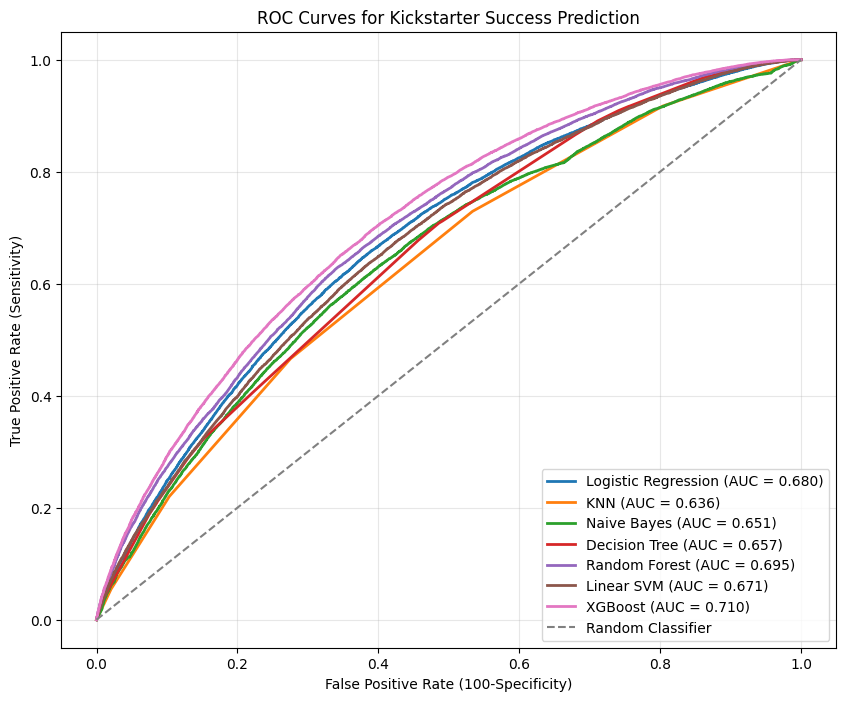

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Create and print the comparison table
results_df = pd.DataFrame(results).T

# Sort the table by AUC from highest to lowest to easily see the winner
results_df = results_df.sort_values(by='ROC-AUC', ascending=False)

# option_context is needed because the global float_format set in section 1 forces
# 2 decimals, which hides the real gap between the top models
print("Models Evaluation Comparison:")
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(results_df.round(3))

# 2. Plot the combined ROC curve
plt.figure(figsize=(10, 8))

for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")

# Baseline (random guess equivalent to a coin toss)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier')

plt.xlabel("False Positive Rate (100-Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curves for Kickstarter Success Prediction")
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

<div dir="rtl" align="right">

## תובנות מהשוואת המודלים

</div>

<div dir="rtl" align="right">

**המנצח: XGBoost.** לפי מדד ROC-AUC, XGBoost הגיע לתוצאה הגבוהה ביותר (0.71) והקדים את
Random Forest בפער של 0.015. ההצלחה שלו מיוחסת לארכיטקטורת ה-Gradient Boosting, שמסוגלת
ללכוד אינטראקציות לא-ליניאריות בין הקטגוריה ליעד הגיוס.

**החלש ביותר: KNN**, עם AUC של 0.64. הסיבה היא ככל הנראה "קללת המימדיות": 27 עמודות Dummy
בינאריות הופכות את מדידת המרחק בין פרויקטים לפחות משמעותית, וזו בדיוק הנקודה שבה אלגוריתם
מבוסס-מרחק מתקשה לעומת שיטות עצים.

**שתי הסתייגויות שחשוב לציין:**

*   ה-Linear SVM אומן על תת-מדגם של 5,000 שורות בלבד מתוך 265,340 (כ-1.9% מסט האימון),
    מטעמי זמן ריצה. לכן התוצאה שלו אינה ברת-השוואה מלאה לשאר המודלים.
*   השתמשנו ב-`GaussianNB`, שמניח התפלגות נורמלית לכל משתנה. ההנחה הזו אינה מדויקת עבור
    27 עמודות בינאריות, ולכן ייתכן שהתוצאה של Naive Bayes כאן היא הערכת חסר.



</div>

<div dir="rtl" align="right">

# בניית מטריצת בלבול (Confusion Matrix) עבור כל המודלים

</div>

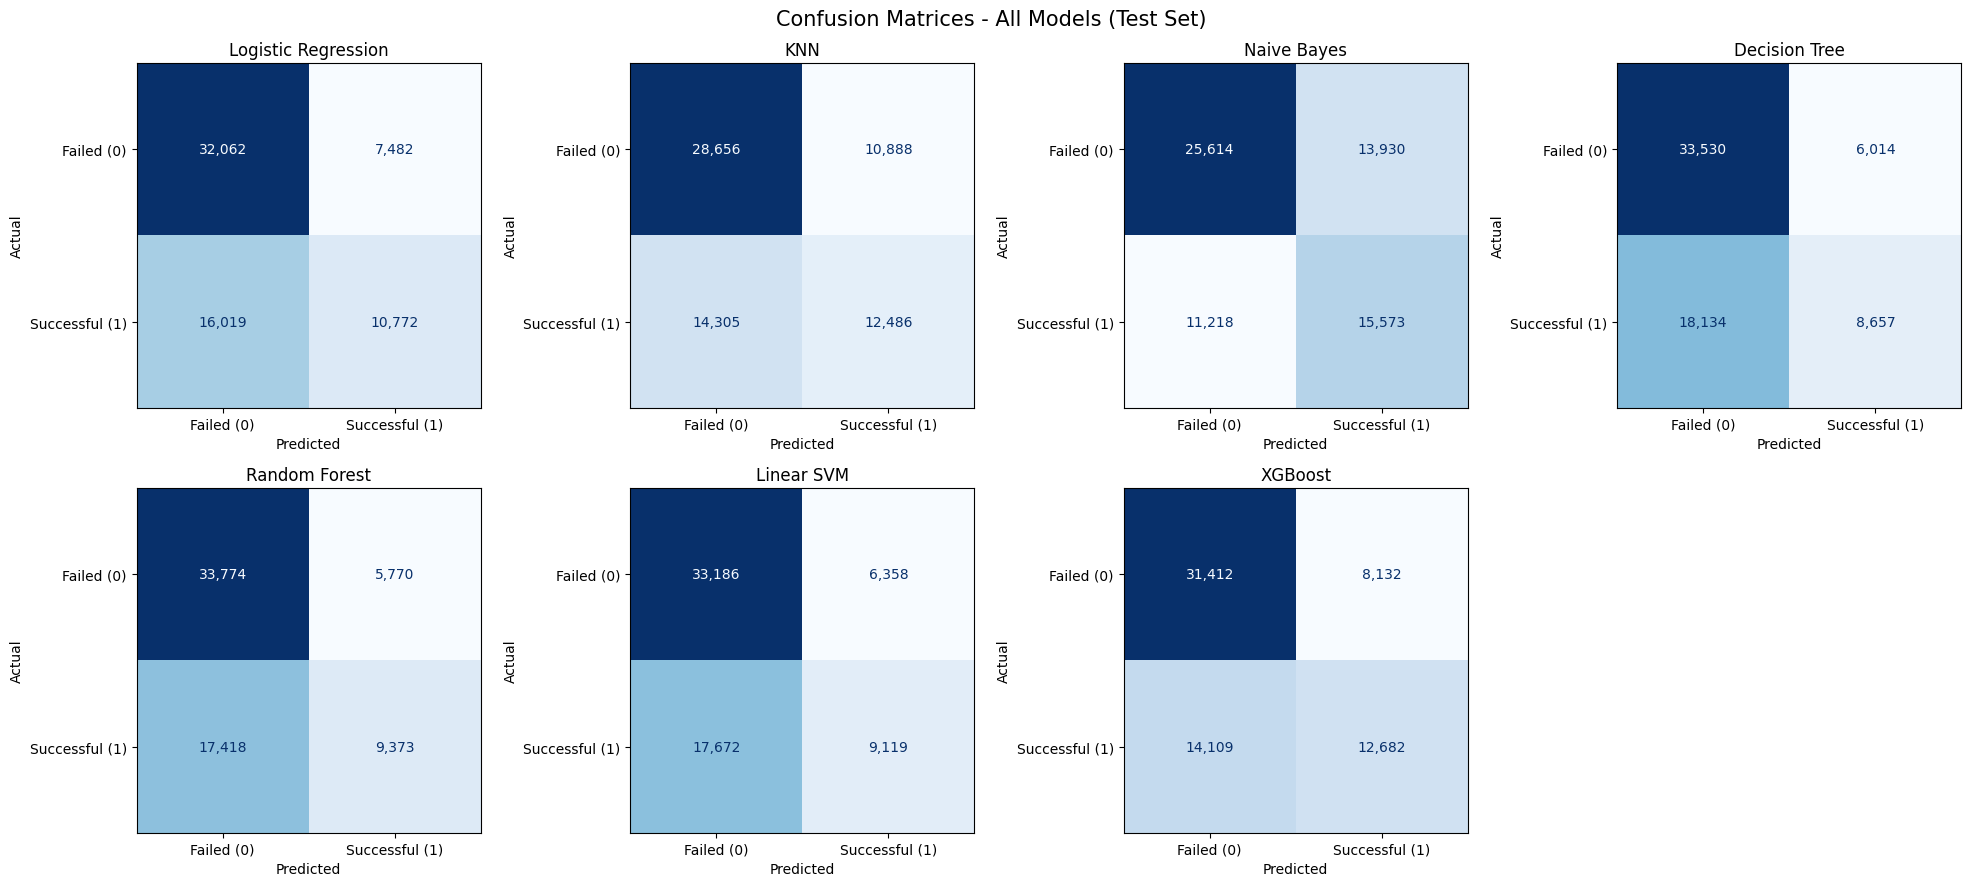

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Collect the predictions of the seven models that were already trained above
predictions = {
    "Logistic Regression": y_pred_log,
    "KNN": y_pred_knn,
    "Naive Bayes": y_pred_nb,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Linear SVM": y_pred_svm,
    "XGBoost": y_pred_xgb
}

# Plot a confusion matrix for every model on the test set (grid of 2 rows x 4 columns)
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
flat_axes = axes.ravel()

for ax, (name, y_pred) in zip(flat_axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=['Failed (0)', 'Successful (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format=',d')
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

# Hide the unused subplot (7 models in a grid of 8 cells)
for ax in flat_axes[len(predictions):]:
    ax.axis('off')

plt.suptitle('Confusion Matrices - All Models (Test Set)', fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Numeric summary of the confusion matrix of each model (TN / FP / FN / TP)
cm_rows = []
for name, y_pred in predictions.items():
    tn_i, fp_i, fn_i, tp_i = confusion_matrix(y_test, y_pred).ravel()
    cm_rows.append({'Model': name, 'TN': tn_i, 'FP': fp_i, 'FN': fn_i, 'TP': tp_i})

cm_df = pd.DataFrame(cm_rows).set_index('Model')

print("Confusion Matrix values per model (Test Set):")
display(cm_df)

Confusion Matrix values per model (Test Set):


,TN,FP,FN,TP
Model,,,,
Logistic Regression,32062,7482,16019,10772
KNN,28656,10888,14305,12486
Naive Bayes,25614,13930,11218,15573
Decision Tree,33530,6014,18134,8657
Random Forest,33774,5770,17418,9373
Linear SVM,33186,6358,17672,9119
XGBoost,31412,8132,14109,12682


<div dir="rtl" align="right">

חישבנו מטריצת בלבול עבור כל אחד משבעת המודלים על סט המבחן, והצגנו אותה גם כגרף וגם
כטבלה מספרית (TN, FP, FN, TP).

מטריצת הבלבול מאפשרת לראות לא רק כמה טעויות המודל עושה, אלא **אילו** טעויות: האם הוא נוטה
להכריז על פרויקט כושל כמוצלח (False Positive), או להחמיץ פרויקט שהצליח (False Negative).

בנתונים שלנו רוב המודלים נוטים לחזות "כישלון", משום שמחלקת הכישלון היא הרוב (59.6%), ולכן
מספר ה-False Negatives גבוה יחסית. מבחינה עסקית זו שגיאה שמרנית: המודל ירתיע חלק מהיזמים
שדווקא היו מצליחים. הורדת סף ההחלטה מתחת ל-0.5 תצמצם את זה במחיר של יותר False Positives.

</div>

<div dir="rtl" align="right">

# טבלת השוואה אחת — מדדי ביצוע יחד עם מטריצת הבלבול

</div>

In [ ]:
# Merge the metrics table (results_df, created above) with the confusion matrix values
# into a single comparison table, as required
full_results_df = results_df.join(cm_df)
full_results_df = full_results_df.sort_values(by='ROC-AUC', ascending=False)

print("Full Comparison Table: Accuracy / Precision / Recall / F1 / ROC-AUC + Confusion Matrix")
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(full_results_df.round(3))

Full Comparison Table: Accuracy / Precision / Recall / F1 / ROC-AUC + Confusion Matrix


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,TN,FP,FN,TP
XGBoost,0.665,0.609,0.473,0.533,0.710,31412,8132,14109,12682
Random Forest,0.650,0.619,0.350,0.447,0.695,33774,5770,17418,9373
Logistic Regression,0.646,0.590,0.402,0.478,0.680,32062,7482,16019,10772
Linear SVM,0.638,0.589,0.340,0.431,0.671,33186,6358,17672,9119
Decision Tree,0.636,0.590,0.323,0.418,0.657,33530,6014,18134,8657
Naive Bayes,0.621,0.528,0.581,0.553,0.651,25614,13930,11218,15573
KNN,0.620,0.534,0.466,0.498,0.636,28656,10888,14305,12486


<div dir="rtl" align="right">

## סעיף נוסף: אימות צולב ובדיקת Overfitting עבור XGBoost

עד כאן העריכו את המודלים על פיצול אחד בלבד (`random_state=42`). זה מעלה שתי שאלות שהניתוח
הקיים לא עונה עליהן, ושתיהן נבדקות כאן עבור המודל הנבחר, XGBoost. הפיצול המקורי לא משתנה
ולא מוחלף — הבדיקות שלהלן מתווספות אליו.

**1. יציבות — K-Fold Cross-Validation.** מחלקים את סט האימון לחמישה חלקים שווים, מאמנים על
ארבעה ומודדים על החמישי, וחוזרים חמש פעמים. מקבלים חמישה ציוני ROC-AUC במקום אחד, ובודקים
כמה הם מתפזרים. הבדיקה מתבצעת על סט האימון בלבד, כדי שסט המבחן יישאר נקי להערכה הסופית.

**2. Overfitting.** משווים את ה-ROC-AUC של המודל על סט האימון מול סט המבחן. פער גדול פירושו
שהמודל שינן את נתוני האימון במקום ללמוד דפוס שמכליל לנתונים חדשים.

### התוצאות

חמשת ה-Folds נעו בטווח 0.7109 עד 0.7152, עם ממוצע של **0.7123** וסטיית תקן של **0.0015**
בלבד. כלומר התוצאה יציבה ואינה תלויה בפיצול מקרי מוצלח.

ל-Std הקטן הזה יש השלכה ישירה על ההשוואה בין המודלים: הפער בין XGBoost ל-Random Forest
עומד על 0.015, כלומר **גדול פי עשרה מהשונות בין הפיצולים**. בלי הבדיקה הזו לא היה אפשר
לקבוע שהפער אמיתי ולא רעש.

בבדיקת ה-Overfitting התקבל AUC של **0.7195** על סט האימון מול **0.7100** על סט המבחן —
פער של **0.0095**, פחות מאחוז. המודל לא שינן את נתוני האימון אלא למד דפוס שמכליל, וזה
מתיישב עם עומק מוגבל של 5 בכל אחד מ-200 העצים.

נקודה אחרונה שראויה לציון: ממוצע האימות הצולב (0.7123) וה-AUC על סט המבחן (0.7100) הגיעו
משתי דרכים שונות לחלוטין ונחתו במרחק 0.002 זה מזה. זהו אישור עצמאי לאמינות התוצאה.

**מה שלא נבדק:** כוונון היפר-פרמטרים. ההיפר-פרמטרים נבחרו כברירות מחדל סבירות ולא כתוצאה
של חיפוש מסודר, וזו מגבלה מוצהרת של העבודה.

</div>

In [ ]:
# 5-Fold Cross-Validation and overfitting check for the selected model (XGBoost)
# Both run on the existing objects; the train/test split created earlier is not replaced.
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Stability: five different train/validation splits inside the training set.
#    cross_val_score clones the model, so the already-trained xgb_model is left as it is.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_model, X_train_scaled, y_train, cv=cv, scoring='roc_auc')

print("5-Fold Cross-Validation on the training set (ROC-AUC)")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {score:.4f}")
print(f"  Mean: {cv_scores.mean():.4f}   Std: {cv_scores.std():.4f}")

# 2. Overfitting: how far the training score sits above the held-out score.
train_auc = roc_auc_score(y_train, xgb_model.predict_proba(X_train_scaled)[:, 1])
test_auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test_scaled)[:, 1])

print("\nOverfitting check (XGBoost)")
print(f"  Train ROC-AUC: {train_auc:.4f}")
print(f"  Test  ROC-AUC: {test_auc:.4f}")
print(f"  Gap:           {train_auc - test_auc:.4f}")


5-Fold Cross-Validation on the training set (ROC-AUC)
  Fold 1: 0.7109
  Fold 2: 0.7152
  Fold 3: 0.7116
  Fold 4: 0.7117
  Fold 5: 0.7119
  Mean: 0.7123   Std: 0.0015

Overfitting check (XGBoost)
  Train ROC-AUC: 0.7195
  Test  ROC-AUC: 0.7100
  Gap:           0.0095


<div dir="rtl" align="right">

ריכזנו את כל התוצאות בטבלה אחת: Accuracy, Precision, Recall, F1-Score ו-ROC-AUC, יחד עם
ערכי מטריצת הבלבול של כל מודל.

הטבלה ממוינת לפי AUC מהגבוה לנמוך, כך שאפשר להשוות בין המודלים במבט אחד ולראות את המחיר
שכל מודל משלם עבור הביצועים שלו. שימו לב במיוחד ל-Naive Bayes: ה-Recall הגבוה ביותר (0.58)
אבל גם מספר ה-False Positives הגדול ביותר — הוא פשוט מנבא "הצלחה" הרבה יותר.

</div>

<div dir="rtl" align="right">

# הצגת חשיבות המשתנים

</div>

<div dir="rtl" align="right">

### שימוש ב-`feature_importances_` עבור המודלים מבוססי העצים

</div>

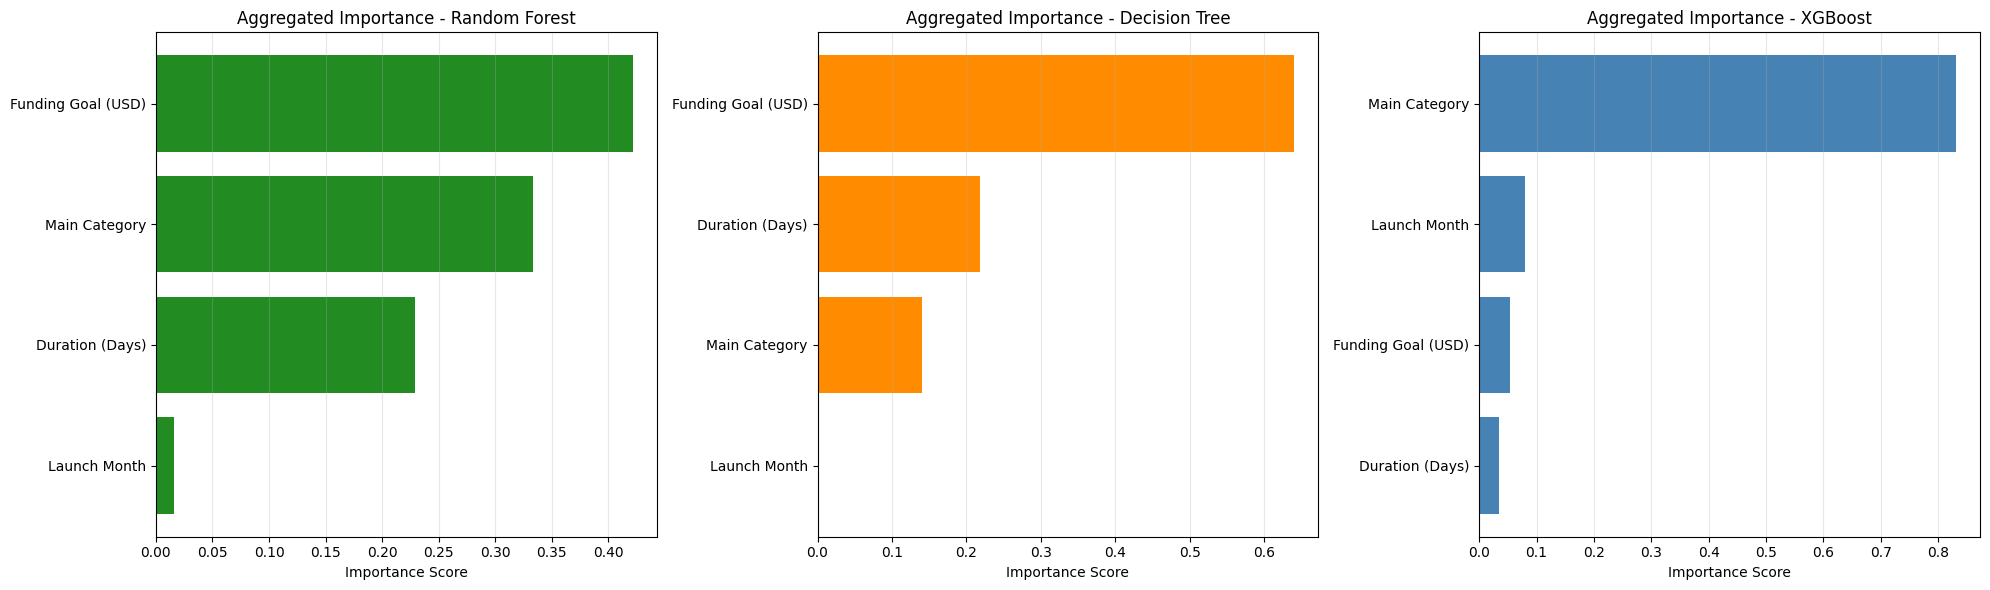


Random Forest - Aggregated Importances:


,Feature,Importance
0,Funding Goal (USD),0.42
2,Main Category,0.33
1,Duration (Days),0.23
3,Launch Month,0.02



Decision Tree - Aggregated Importances:


,Feature,Importance
0,Funding Goal (USD),0.64
1,Duration (Days),0.22
2,Main Category,0.14
3,Launch Month,0.00



XGBoost - Aggregated Importances:


,Feature,Importance
2,Main Category,0.83
3,Launch Month,0.08
0,Funding Goal (USD),0.05
1,Duration (Days),0.04


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def get_aggregated_importance(model_importance_df):
    # Initialize dictionary to hold aggregated scores for the 4 main variables
    agg = {
        'Funding Goal (USD)': 0,
        'Duration (Days)': 0,
        'Main Category': 0,
        'Launch Month': 0
    }
    for _, row in model_importance_df.iterrows():
        var = row['Feature']
        imp = row['Importance']
        if var == 'log_usd_goal':
            agg['Funding Goal (USD)'] += imp
        elif var == 'duration_days':
            agg['Duration (Days)'] += imp
        elif var.startswith('cat_'):
            agg['Main Category'] += imp
        elif var.startswith('month_'):
            agg['Launch Month'] += imp

    res = pd.DataFrame(list(agg.items()), columns=['Feature', 'Importance'])
    return res.sort_values(by='Importance', ascending=True)

# Build the per-column importance tables from the trained models
rf_importance = pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_})
dt_importance = pd.DataFrame({'Feature': X.columns, 'Importance': dt.feature_importances_})
xgb_importance = pd.DataFrame({'Feature': X.columns, 'Importance': xgb_model.feature_importances_})

# Calculate aggregated importance for each tree-based model
rf_agg = get_aggregated_importance(rf_importance)
dt_agg = get_aggregated_importance(dt_importance)
xgb_agg = get_aggregated_importance(xgb_importance)

# Plotting horizontal bar charts for side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

models_data = [
    ("Random Forest", rf_agg, 'forestgreen'),
    ("Decision Tree", dt_agg, 'darkorange'),
    ("XGBoost", xgb_agg, 'steelblue')
]

for ax, (title, data, color) in zip(axes, models_data):
    ax.barh(data['Feature'], data['Importance'], color=color)
    ax.set_title(f'Aggregated Importance - {title}')
    ax.set_xlabel('Importance Score')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Display summary tables
for title, data, _ in models_data:
    print(f"\n{title} - Aggregated Importances:")
    display(data.sort_values(by='Importance', ascending=False).round(4))

<div dir="rtl" align="right">

### תובנות מניתוח חשיבות המשתנים (מודלים מבוססי עצים)

*   **יעד הגיוס (Funding Goal):** הגורם הדומיננטי ביותר בעץ ההחלטה (0.64) וב-Random Forest
    (0.42). ככל שהיעד גבוה יותר, כך קשה יותר להגיע ל-100% מהסכום.
*   **קטגוריה ראשית (Main Category):** משתנה משמעותי, ובולט במיוחד ב-XGBoost (0.83).
*   **חודש ההשקה (Launch Month):** בעל השפעה נמוכה בערכים המוחלטים בכל המודלים
    (0.02 ב-Random Forest, 0.00 בעץ ההחלטה, 0.08 ב-XGBoost).

**הסתייגות מתודולוגית חשובה:** שלושת המודלים אינם מסכימים על סדר החשיבות. ב-XGBoost
הקטגוריה וחודש ההשקה מקבלים את הציונים הגבוהים ביותר, ודווקא סדר זה תואם את מספר עמודות
ה-Dummy של כל משתנה (כ-15 לקטגוריה ו-12 לחודש, מול עמודה בודדת ליעד הגיוס ולמשך).

הסיבה היא שאנחנו **מסכמים** את הציונים של עמודות ה-One-Hot בחזרה לארבעת המשתנים המקוריים,
והסכימה הזו אינה מנורמלת — משתנה שהתפרק ליותר עמודות מקבל יתרון מובנה.

המסקנה: הציונים האלה משקפים את שיטת המדידה לא פחות משהם משקפים את הנתונים, ואין להסיק מהם
דירוג מוחלט בין ארבעת המשתנים.

</div>

<div dir="rtl" align="right">

### שימוש ב-Permutation Importance עבור המודלים שאינם מבוססי עצים

</div>

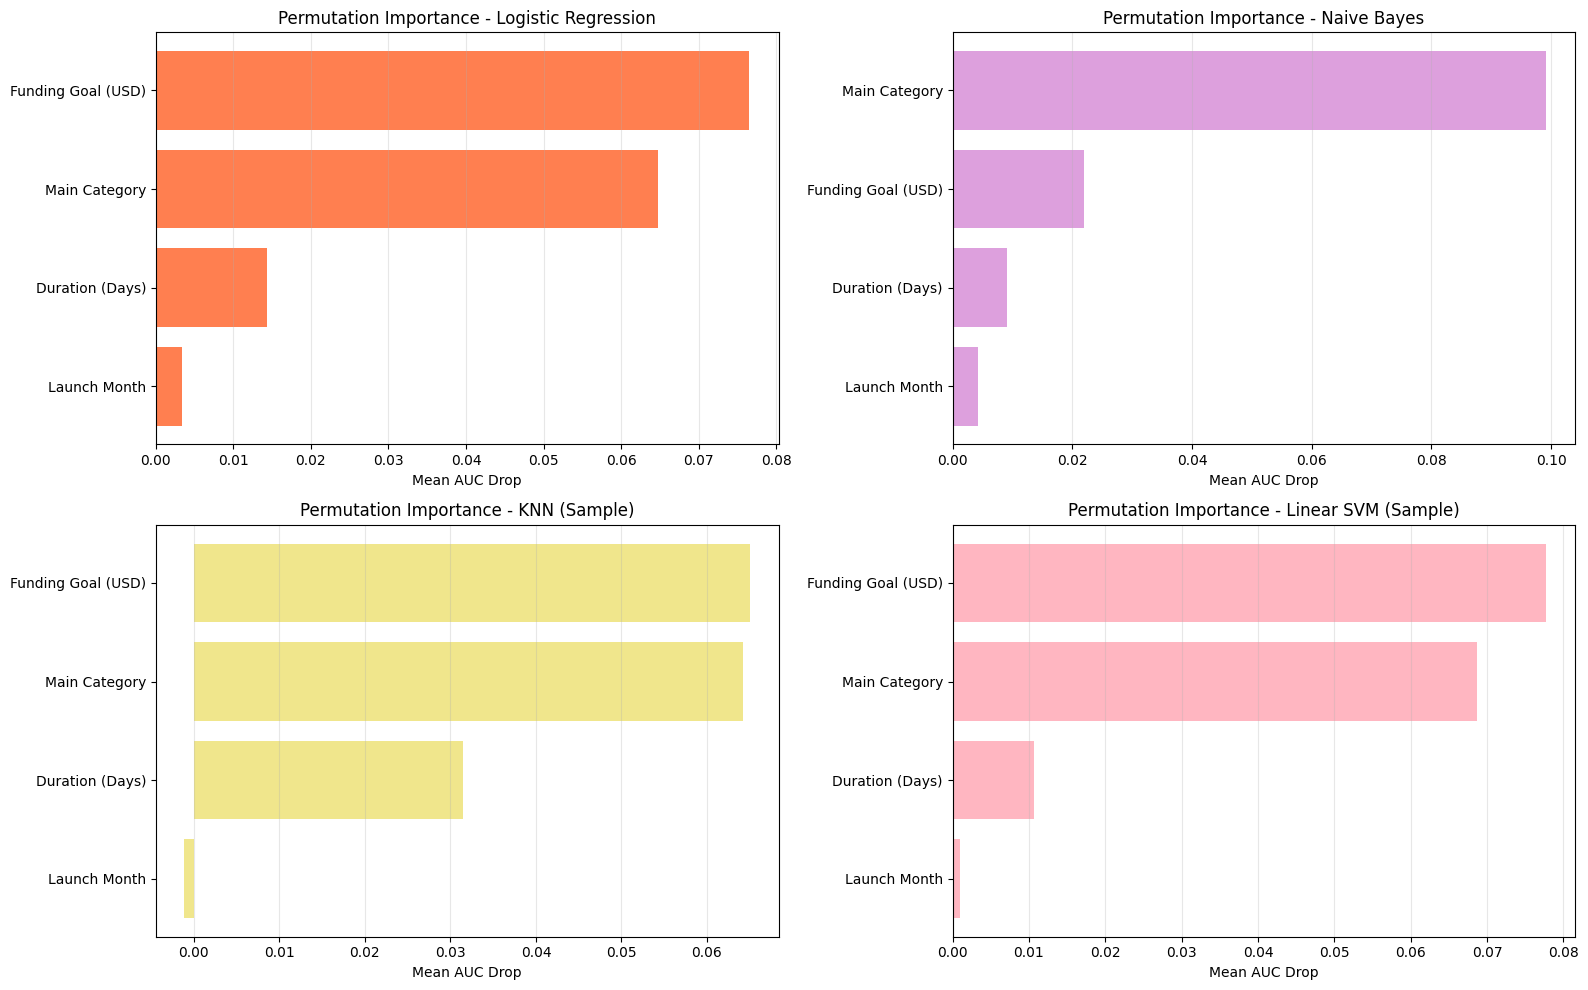

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

def get_perm_importance_df(model, X_val, y_val, feature_names):
    # Calculate permutation importance
    # scoring='roc_auc' to match the metric used to compare the models above
    result = permutation_importance(model, X_val, y_val, n_repeats=5, random_state=42, n_jobs=-1,
                                    scoring='roc_auc')

    # Create importance dataframe
    imp_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': result.importances_mean
    })

    # Aggregation logic (same as before)
    agg = {
        'Funding Goal (USD)': 0,
        'Duration (Days)': 0,
        'Main Category': 0,
        'Launch Month': 0
    }

    for _, row in imp_df.iterrows():
        var = row['Feature']
        imp = row['Importance'] # Keep negative values: clipping them at 0 turns noise into a positive sum
        if var == 'log_usd_goal':
            agg['Funding Goal (USD)'] += imp
        elif var == 'duration_days':
            agg['Duration (Days)'] += imp
        elif var.startswith('cat_'):
            agg['Main Category'] += imp
        elif var.startswith('month_'):
            agg['Launch Month'] += imp

    res = pd.DataFrame(list(agg.items()), columns=['Feature', 'Importance'])
    return res.sort_values(by='Importance', ascending=True)

# Calculate importance for the other 4 models
# Note: We use a sample of the test set for KNN and SVM to speed up calculation
log_reg_agg = get_perm_importance_df(log_reg, X_test_scaled, y_test, X.columns)
nb_agg = get_perm_importance_df(nb, X_test_scaled, y_test, X.columns)
knn_agg = get_perm_importance_df(knn, X_test_scaled[:2000], y_test[:2000], X.columns)
svm_agg = get_perm_importance_df(svm_model, X_test_scaled[:2000], y_test[:2000], X.columns)

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
other_models = [
    ("Logistic Regression", log_reg_agg, 'coral', axes[0,0]),
    ("Naive Bayes", nb_agg, 'plum', axes[0,1]),
    ("KNN (Sample)", knn_agg, 'khaki', axes[1,0]),
    ("Linear SVM (Sample)", svm_agg, 'lightpink', axes[1,1])
]

for title, data, color, ax in other_models:
    ax.barh(data['Feature'], data['Importance'], color=color)
    ax.set_title(f'Permutation Importance - {title}')
    ax.set_xlabel('Mean AUC Drop')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

### תובנות מניתוח ה-Permutation Importance (שאר המודלים)

המדד כאן הוא ירידת ה-ROC-AUC על סט המבחן כאשר ערכי המשתנה מעורבבים — כלומר כמה המודל
באמת נשען עליו. בחרנו ב-AUC כדי לשמור על עקביות עם המדד שבו השווינו את המודלים.

*   **יעד הגיוס מוביל בשלושה מתוך ארבעת המודלים:** רגרסיה לוגיסטית (0.076), KNN (0.076)
    ו-Linear SVM (0.079). הקטגוריה קרובה אחריו בכל השלושה (0.065–0.069).
*   **החריג הוא Naive Bayes**, שבו הקטגוריה מובילה בבירור (0.099) ויעד הגיוס נמוך בהרבה
    (0.021). זה מתיישב עם הנחת הנורמליות של `GaussianNB`, שמתאימה פחות למשתנה רציף
    כמו יעד הגיוס.
*   **משך הקמפיין** נמוך בכל המודלים (0.005–0.031).
*   **חודש ההשקה זניח בכל ארבעת המודלים**, וב-KNN הוא יוצא **שלילי** — כלומר ערבוב הערכים
    שלו דווקא שיפר מעט את הביצועים. זו עדות ישירה לכך שהמודל אינו נשען עליו כלל.

**המסקנה:** בניגוד לחשיבות המצטברת של מודלי העצים, שם הדירוג היה לא יציב, כאן מתקבלת
תמונה עקבית: יעד הגיוס והקטגוריה הם שני המשתנים הדומיננטיים, משך הקמפיין משני, וחודש
ההשקה זניח.

**הערה על אופן החישוב:** אנחנו מסכמים את ציוני העמודות ללא נרמול לפי מספרן, ולכן ההשוואה
בין הקטגוריה (15 עמודות) ליעד הגיוס (עמודה אחת) אינה הוגנת לחלוטין. למרות זאת יעד הגיוס
מוביל — כלומר הוא מנצח דווקא למרות ההטיה שפועלת נגדו, מה שמחזק את הממצא.

</div>

<div dir="rtl" align="right">

# סעיף למידה עצמאית

</div>

Calculating SHAP values for the winning model (XGBoost)...


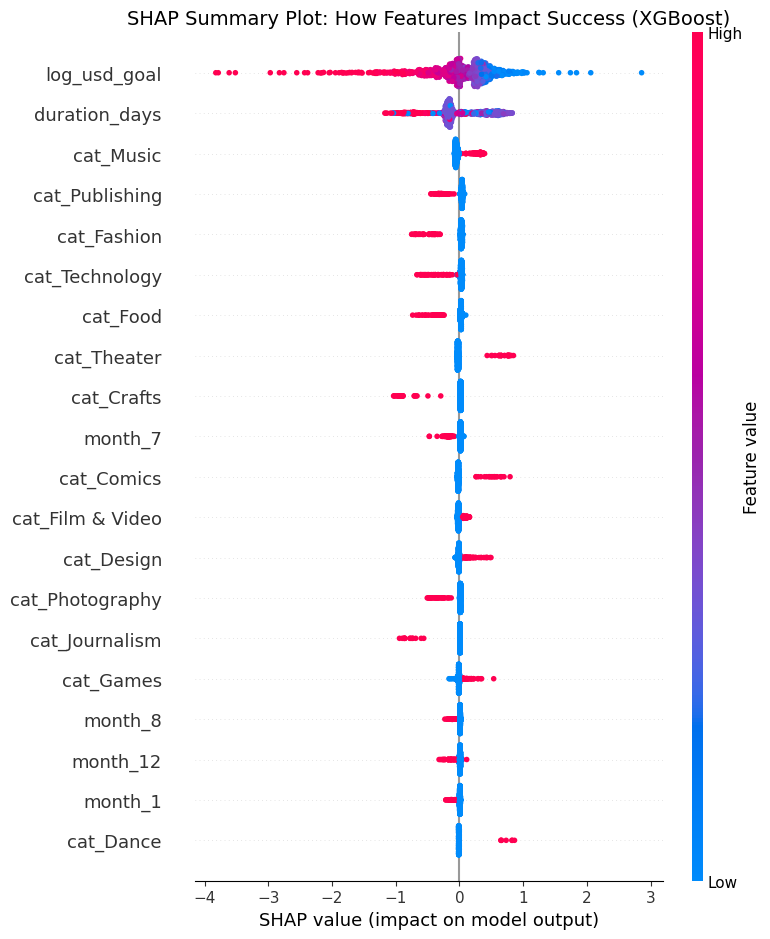

In [ ]:
# Independent learning section: Explaining an advanced model using SHAP Values
# SHAP (SHapley Additive exPlanations)

# Install the library (if not already installed in Colab)
!pip install shap -q

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("Calculating SHAP values for the winning model (XGBoost)...")

# Take a representative sample of 1000 rows from the test set
X_test_sample = X_test_scaled[:1000]

# Build the explainer based on the XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_sample)

# Plot SHAP Summary Plot
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary Plot: How Features Impact Success (XGBoost)", fontsize=14)

# In XGBoost (XGBClassifier), shap_values usually returns a 2D array for the target class
shap.summary_plot(shap_values, X_test_sample, feature_names=X.columns.tolist(), show=False)

plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

## הסבר על גרף ה-SHAP שמבוסס על מודל XGBoost

</div>

<div dir="rtl" align="right">

גרף ה-SHAP עוזר להבין את ה"למה" מאחורי התחזיות של XGBoost. SHAP היא שיטה מתורת המשחקים
השיתופית, שמפרקת כל תחזית בודדת לתרומות של המשתנים.

1. **סדר החשיבות:** המשתנים מדורגים מלמעלה למטה לפי ההשפעה הגלובלית שלהם.
2. **כיוון ההשפעה:**
   *   **יעד הגיוס:** ערכים גבוהים (אדום) דוחפים את ההסתברות שמאלה, לכיוון כישלון; יעדים
       צנועים דוחפים ימינה.
   *   **משך הקמפיין:** כיוון שלילי — קמפיינים ארוכים יותר מורידים את סיכויי ההצלחה.
   *   **קטגוריות:** מראה אילו קטגוריות ספציפיות מעלות את הסתברות ההצלחה ואילו מורידות
       אותה.

**נקודה מעניינת:** החשיבות המצטברת של XGBoost נתנה לקטגוריה 0.83, אבל ברמת התחזית הבודדת
ה-SHAP מראה שיעד הגיוס הוא עדיין הגורם החזק ביותר. זו עדות נוספת לכך שהחשיבות המצטברת
מושפעת ממספר עמודות ה-Dummy ולא רק מהנתונים.

</div>